# The simulations of the note, step by step

This notebook runs the code behind *Voting for a consensus with veto rights* one step at a time. It imports
the modules of `simulations/python/`, the same code that writes every table and figure of the note, so nothing
here is a copy that could drift from it.

| Module | What it holds |
|---|---|
| `voting.py` | an election (rankings and vetoes), the 21 rules, QVC(θ), the proportional veto core |
| `cultures.py` | the random electorates: spatial, polarised (55/45), impartial |
| `examples.py` | the worked examples E1–E4 of Section 6.4 |
| `experiments.py` | the Monte Carlo study: seeds, measures, one election at a time |

1. A ballot profile by hand: Example E1
2. The four worked examples
3. Flooding the agenda: Example E2
4. One simulated election, drawn
5. The polarised electorate: the note's table, recomputed
6. The blocking quota θ
7. Deadlock as the assembly grows
8. The checks of the code

Every election is drawn from its own seed, as in the note, so sections 5–7 reproduce the note's tables exactly.
The whole notebook runs in under a minute. It needs `simulations/python/requirements.txt` and Jupyter
(`pip install jupyter`); open it from anywhere inside the repository.

In [1]:
import csv
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "simulations/python/voting.py").exists())
sys.path.insert(0, str(ROOT / "simulations/python"))

import matplotlib.pyplot as plt
import numpy as np

import cultures as C
import examples as EX
import experiments as X
import voting as V

TABLES = ROOT / "outputs/tables"


def show(header, rows):
    """Print a small table with aligned columns."""
    cells = [[str(c) for c in header]] + [[str(c) for c in r] for r in rows]
    width = [max(len(r[j]) for r in cells) for j in range(len(header))]
    for k, r in enumerate(cells):
        print("  ".join(c.ljust(w) if j == 0 else c.rjust(w) for j, (c, w) in enumerate(zip(r, width))))
        if k == 0:
            print("  ".join("-" * w for w in width))


def note_table(name):
    """A table of the note, as written by experiments.py: {row label: row}."""
    with open(TABLES / f"{name}.csv", encoding="utf8") as fh:
        rows = list(csv.reader(fh))
    return rows[0], {r[0]: r for r in rows[1:]}


print("Modules loaded:", ", ".join(m.__name__ for m in (V, C, EX, X)))
print(len(V.RULES), "rules:", ", ".join(V.RULES))

Modules loaded: voting, cultures, examples, experiments
21 rules: Plurality, IRV, Borda, Approval, Majority Judgment, Copeland, Minimax, Schulze, Ranked Pairs, Split Cycle, Fallback, Fallback (impasse), Majoritarian compromise, Sequential veto, Unanimity, PVC + Schulze, QVC individual, QVC 10%, QVC 25%, QVC 33%, QVC 50%


## 1. A ballot profile by hand: Example E1

An `Election` holds, for each voter, a utility for every option (only the order matters: it is the voter's
ranking) and an acceptability mark (`False` is a veto). In Example E1, 51 voters rank A ≻ B ≻ C and veto C;
49 rank B ≻ C ≻ A and veto A. The status quo is C.

In [2]:
e1 = EX.EXAMPLES["E1"][1]
print("options:", e1.names, "| voters:", e1.n, "| status quo:", e1.names[e1.sq])
print("veto counts v(x):", dict(zip(e1.names, e1.vetoes().tolist())))
print()
show(["N(x, y)"] + e1.names, [[x] + e1.N()[i].tolist() for i, x in enumerate(e1.names)])

options: ['A', 'B', 'C'] | voters: 100 | status quo: C
veto counts v(x): {'A': 49, 'B': 0, 'C': 51}

N(x, y)   A   B    C
-------  --  --  ---
A         0  51   51
B        49   0  100
C        49   0    0


A beats B and C by 51 to 49: it is the Condorcet winner, and the Schulze method elects it. QVC(θ) first
excludes every option vetoed by at least θn voters, then elects the Schulze winner among the options left. The
quota decides between the majority's A and the compromise B (Proposition 1):

In [3]:
for theta in (0.25, 1 / 3, 0.49, 0.50):
    winners, fell_back = V.qvc(e1, theta)
    admissible = [e1.names[x] for x in np.flatnonzero(e1.vetoes() < theta * e1.n - 1e-9)]
    print(f"theta = {theta:.2f}, theta*n = {theta * e1.n:5.1f}: admissible {admissible}, "
          f"QVC elects {[e1.names[w] for w in winners]}")
print()
print("Schulze, no quota, elects", e1.names[V.run(e1, "Schulze").winner])
print("Proportional veto core:", [e1.names[x] for x in V.pvc(e1)])

theta = 0.25, theta*n =  25.0: admissible ['B'], QVC elects ['B']
theta = 0.33, theta*n =  33.3: admissible ['B'], QVC elects ['B']
theta = 0.49, theta*n =  49.0: admissible ['B'], QVC elects ['B']
theta = 0.50, theta*n =  50.0: admissible ['A', 'B'], QVC elects ['A']

Schulze, no quota, elects A
Proportional veto core: ['B']


## 2. The four worked examples

`examples.winners()` applies nine rules to the four profiles of Section 6.4: E1 (majority or compromise), E2
(E1 flooded with two variants of A), E3 (a Condorcet cycle) and E4 (one voter against the status quo's
replacement). This is Table 4 of the note. *(stuck)*: no proposal passes and the status quo stays; *(fb)*: every
option is vetoed by the quota and QVC keeps the least-vetoed ones.

In [4]:
w = EX.winners()
show(["Example"] + [EX.SHORT[r] for r in EX.RULES],
     [[f"{k} ({EX.TAG[k]})"] + [w[k][r] for r in EX.RULES] for k in EX.EXAMPLES])

Example          Plur.  Borda  Schul.  Fallb.  PVC      Unan.   Q 25%  Q 33%  Q 50%
---------------  -----  -----  ------  ------  ---  ---------  ------  -----  -----
E1 (compromise)      A      B       A       B    B          B       B      B      A
E2 (flooding)        A      A       A       A    A          B       B      B      A
E3 (cycle)           A      A       A       B    A  C (stuck)  B (fb)      A      A
E4 (status quo)      X      X       X       Y    X  S (stuck)       X      X      X


## 3. Flooding the agenda: Example E2

In E2 the majority adds two variants of A, A2 and A3, which it ranks just below A; the minority ranks them last
and vetoes them. The proportional veto core counts veto power in options: 49% of five options is two vetoes,
which no longer cover three copies of A, so A enters the core (Proposition 3). Under the blocking quota each
variant inherits the minority's 49 vetoes and is excluded with A (Proposition 7).

In [5]:
for key in ("E1", "E2"):
    e = EX.EXAMPLES[key][1]
    print(f"{key}: vetoes {dict(zip(e.names, e.vetoes().tolist()))}")
    print(f"    proportional veto core {[e.names[x] for x in V.pvc(e)]} -> PVC + Schulze elects "
          f"{e.names[V.run(e, 'PVC + Schulze').winner]}")
    print(f"    QVC(1/3) elects {e.names[V.run(e, 'QVC 33%').winner]}")

E1: vetoes {'A': 49, 'B': 0, 'C': 51}
    proportional veto core ['B'] -> PVC + Schulze elects B
    QVC(1/3) elects B
E2: vetoes {'A': 49, 'A2': 49, 'A3': 49, 'B': 0, 'C': 51}
    proportional veto core ['A'] -> PVC + Schulze elects A
    QVC(1/3) elects B


## 4. One simulated election, drawn

The first election of the note's polarised electorate: 101 voters in two blocs (55% and 45%), seven proposals
made by voters near their own position, and the status quo. A voter vetoes the options beyond a personal
tolerance, fixed before the proposals are known.

Option  Vetoed by (%)                                       Elected by
------  -------------  -----------------------------------------------
P0                 63                                                -
P1                 18  Borda, Schulze, PVC + Schulze, QVC 25%, QVC 33%
P2                 32                                                -
P3                 43                                        Plurality
P4                 49                                                -
P5                 45                                                -
P6                 58                                                -
S                  27                                        Unanimity

Condorcet winner: P1


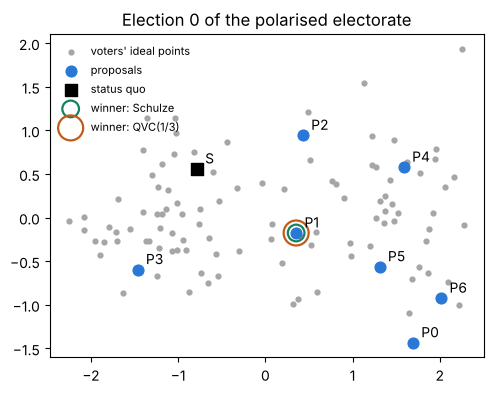

In [6]:
rng = X.rng_for("polarised", 0)                       # the seed of election 0 in the note's study
e, pos_v, pos_x = C.draw("polarised", rng, X.N_VOTERS, X.N_OPTIONS, positions=True)
names = [f"P{x}" for x in range(e.m - 1)] + ["S"]       # proposals P0-P6, status quo S
rules = ["Plurality", "Borda", "Schulze", "PVC + Schulze", "Unanimity", "QVC 25%", "QVC 33%"]
outcomes = {r: V.run(e, r) for r in rules}

show(["Option", "Vetoed by (%)", "Elected by"],
     [[names[x], f"{100 * e.vetoes()[x] / e.n:.0f}",
       ", ".join(r for r in rules if outcomes[r].winner == x) or "-"] for x in range(e.m)])
cw = V.condorcet_winner(e)
print()
print("Condorcet winner:", names[cw] if cw is not None else "none")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(pos_v[:, 0], pos_v[:, 1], s=12, color="0.65", label="voters' ideal points")
ax.scatter(pos_x[:-1, 0], pos_x[:-1, 1], s=60, color="#2A78D6", label="proposals")
ax.scatter(pos_x[-1:, 0], pos_x[-1:, 1], s=80, color="black", marker="s", label="status quo")
for x in range(e.m):
    ax.annotate(names[x], pos_x[x], xytext=(6, 4), textcoords="offset points", fontsize=10)
for r, ring in (("Schulze", 12), ("QVC 33%", 18)):
    w_ = outcomes[r].winner
    ax.scatter(*pos_x[w_], s=ring ** 2, facecolors="none", edgecolors="#C25A1A" if r == "QVC 33%" else "#16825C",
               linewidths=1.6, label=f"winner: {r.replace('QVC 33%', 'QVC(1/3)')}")
ax.set_aspect("equal")
ax.legend(loc="upper left", fontsize=8, frameon=False)
ax.set_title("Election 0 of the polarised electorate")
plt.show()

Adding three clones of an option changes the outcome of some rules and not of others. `work_clones` does it
for this election, as in the note's clone table: first three clones of a losing option drawn at random (teaming,
or flooding), then three clones of the winner (vote splitting).

In [7]:
changed = X.work_clones(("polarised", 0))
show(["Rule", "clones of a loser change it", "clones of the winner change it"],
     [[r, "yes" if changed[r][0] else "no", "yes" if changed[r][1] else "no"] for r in rules])

Rule           clones of a loser change it  clones of the winner change it
-------------  ---------------------------  ------------------------------
Plurality                               no                             yes
Borda                                   no                              no
Schulze                                 no                              no
PVC + Schulze                           no                              no
Unanimity                               no                              no
QVC 25%                                 no                              no
QVC 33%                                 no                              no


## 5. The polarised electorate: the note's table, recomputed

`experiments.work_perf` draws one election from its seed, runs all 21 rules and measures each winner:

- Condorcet efficiency;
- utility efficiency, 0 for the average option and 100 for the best;
- worst-off efficiency, the same for the voter at the 10th percentile;
- contested: vetoed by at least a third of the voters;
- deadlock.

With the note's 2,000 elections, the means are exactly those of Table 5 (`outputs/tables/perf_polarised.csv`).
With fewer elections, set below, they differ within Monte Carlo error. This takes about 20 seconds.

In [8]:
N_ELECTIONS = 2000                                      # the note's number
res = [X.work_perf(("polarised", k)) for k in range(N_ELECTIONS)]

shown = ["Plurality", "Borda", "Approval", "Fallback", "Unanimity", "Schulze", "PVC + Schulze", "QVC 25%", "QVC 33%"]
cols = ["condorcet", "sue", "worst_off", "contested", "deadlock"]
header, note = note_table("perf_polarised")
rows, same = [], True
for r in shown:
    ours = [X.pct(X.mean_of(res, r, m)) for m in cols]
    theirs = [note[X.LABEL.get(r, r)][1 + X.MEASURES.index(m)] for m in cols]
    same &= ours == theirs
    rows.append([X.LABEL.get(r, r)] + ours)
show(["Rule (%)", "Condorcet eff.", "Utility eff.", "Worst-off eff.", "Contested", "Deadlock"], rows)
print()
print(f"{N_ELECTIONS} elections:", "every value equals the note's table" if same else "values differ from the note's table")

Rule (%)       Condorcet eff.  Utility eff.  Worst-off eff.  Contested  Deadlock
-------------  --------------  ------------  --------------  ---------  --------
Plurality                22.4          34.4            13.3       62.1       0.0
Borda                    71.2          94.5            79.1       15.2       0.0
Approval                 72.2          95.5            95.0        5.9       0.0
Fallback                 53.7          87.7            79.9       18.6       0.0
Unanimity                16.2           8.5            30.7       57.4      97.9
Schulze                 100.0          97.4            85.2       10.1       0.0
PVC + Schulze            90.8          96.2            86.7       10.2       0.0
QVC, 25%                 83.2          96.8            92.8        5.9       0.0
QVC, 33%                 94.3          97.7            88.4        5.9       0.0

2000 elections: every value equals the note's table


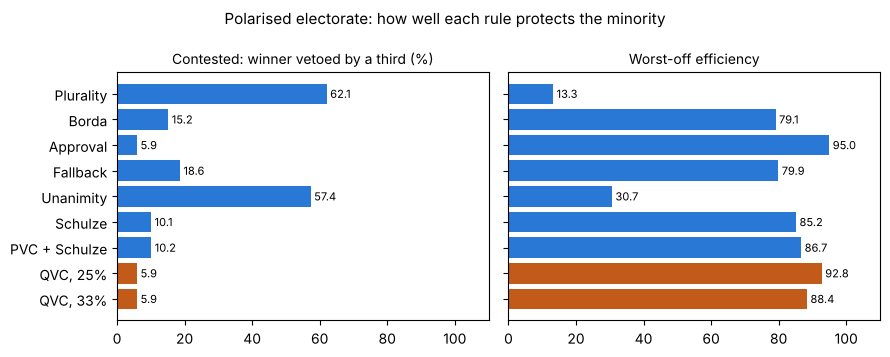

In [9]:
labels = [X.LABEL.get(r, r) for r in shown]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, m, title in ((axes[0], "contested", "Contested: winner vetoed by a third (%)"),
                     (axes[1], "worst_off", "Worst-off efficiency")):
    vals = [100 * X.mean_of(res, r, m) for r in shown]
    colours = ["#C25A1A" if r.startswith("QVC") else "#2A78D6" for r in shown]
    ax.barh(labels, vals, color=colours)
    for y, v in enumerate(vals):
        ax.text(v + 1, y, f"{v:.1f}", va="center", fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, 110)
axes[0].invert_yaxis()
fig.suptitle("Polarised electorate: how well each rule protects the minority", fontsize=11)
plt.tight_layout()
plt.show()

Unanimity is contested most often and serves the worst-off badly: it keeps the status quo. QVC(1/3) cuts the
contested outcomes of Schulze and raises worst-off efficiency, without losing total utility (previous table).
Approval does as well on these two measures but elects the Condorcet winner far less often.

## 6. The blocking quota θ

`experiments.work_theta` runs QVC for every quota from a single veto (1/n) to none (the Schulze rule) on the same
election. The note uses 1,000 elections per electorate; the measures recomputed here equal its Table 10
(`theta_sweep.csv`). Manipulability takes much longer to compute and is read from that table.

1000 elections: the recomputed measures equal the note's table


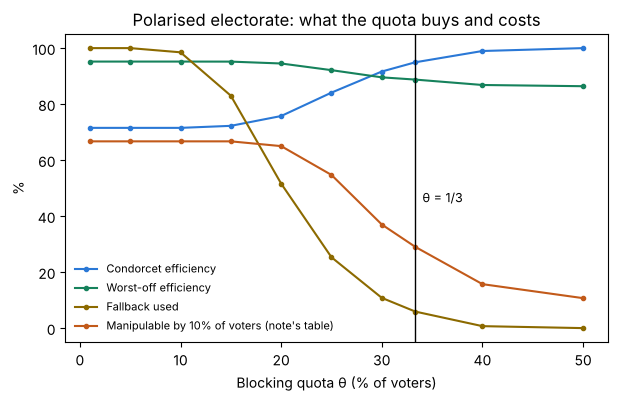

In [10]:
N_THETA = 1000
res_t = [X.work_theta(("polarised", k, False)) for k in range(N_THETA)]
header_t, note_t = note_table("theta_sweep")

thetas = [t for t in X.THETAS if t != 1.0]
xs = [1.0 if t == "1/n" else 100 * t for t in thetas]
label = {t: "1/n (any veto)" if t == "1/n" else f"{100 * t:.0f}%" for t in thetas}
series = {m: [100 * X.mean_of(res_t, str(t), m) for t in thetas] for m in ("condorcet", "worst_off", "fallback")}
manip = [float(note_t[f"Polarised, {label[t]}"][header_t.index("Manip. 10% (%)")]) for t in thetas]
same = all(X.pct(X.mean_of(res_t, str(t), m)) == note_t[f"Polarised, {label[t]}"][header_t.index(X.HEAD[m])]
           for t in thetas for m in series)
print(f"{N_THETA} elections:", "the recomputed measures equal the note's table" if same else "the measures differ from the note's table")

fig, ax = plt.subplots(figsize=(7, 4))
for m, lab, col in (("condorcet", "Condorcet efficiency", "#2A78D6"), ("worst_off", "Worst-off efficiency", "#16825C"),
                    ("fallback", "Fallback used", "#8C6A00")):
    ax.plot(xs, series[m], marker="o", ms=3, color=col, label=lab)
ax.plot(xs, manip, marker="o", ms=3, color="#C25A1A", label="Manipulable by 10% of voters (note's table)")
ax.axvline(100 / 3, color="black", lw=1)
ax.text(100 / 3 + 0.7, 45, "θ = 1/3", fontsize=9)
ax.set_xlabel("Blocking quota θ (% of voters)")
ax.set_ylabel("%")
ax.set_title("Polarised electorate: what the quota buys and costs")
ax.legend(fontsize=8, frameon=False, loc="lower left")
plt.show()

## 7. Deadlock as the assembly grows

Unanimity with the status quo as default keeps the status quo whenever no proposal is preferred to it by every
voter. That is certain once the status quo lies in the convex hull of the voters' ideal points, an event whose
probability tends to one as the assembly grows (Proposition 2). QVC never deadlocks: when every option is vetoed
by the quota, it keeps the least-vetoed ones. Same seeds as the note's Table 11 (`deadlock_n.csv`); a few seconds.

In [11]:
N_DEADLOCK = 1000
ns = [3, 11, 51, 101]
header_d, note_d = note_table("deadlock_n")
rows, curves, same = [], {k: [] for k in ("hull", "Unanimity", "QVC 33%")}, True
for n in ns:
    r = [X.work_deadlock((n, k)) for k in range(N_DEADLOCK)]
    vals = {k: np.mean([x[k] for x in r]) for k in ("hull", "Unanimity", "QVC 25%", "QVC 33%")}
    for k in curves:
        curves[k].append(100 * vals[k])
    ours = [X.pct(vals[k]) for k in ("hull", "Unanimity", "QVC 25%", "QVC 33%")]
    same &= ours == [note_d[str(n)][1], note_d[str(n)][2], note_d[str(n)][4], note_d[str(n)][5]]
    rows.append([n] + ours)
show(["Voters", "Status quo in the hull (%)", "Unanimity: deadlock (%)", "QVC 25%: fallback (%)", "QVC 33%: fallback (%)"], rows)
print()
print(f"{N_DEADLOCK} elections per row:", "every value equals the note's table" if same else "values differ from the note's table")

Voters  Status quo in the hull (%)  Unanimity: deadlock (%)  QVC 25%: fallback (%)  QVC 33%: fallback (%)
------  --------------------------  -----------------------  ---------------------  ---------------------
3                              7.4                     43.3                   29.0                   29.0
11                            50.5                     85.8                   24.2                    7.7
51                            85.7                     98.4                   12.8                    2.5
101                           92.8                     99.6                    8.9                    0.8

1000 elections per row: every value equals the note's table


## 8. The checks of the code

The three scripts carry checks against brute force and known results. Those of `voting.py` and `examples.py`
run in a few seconds and are run here; `python3 simulations/python/experiments.py --check`, which tests the
Monte Carlo against known probabilities with large electorates, is better run from a terminal.

In [12]:
print("voting.py --check")
ok_rules = V.check()
print()
print("examples.py --check")
ok_examples = EX.check()
print()
print("All checks passed" if ok_rules and ok_examples else "Some checks FAILED")

voting.py --check


  PVC: max-flow test = definition by enumeration                 ok
  PVC: never empty (Moulin, 1981)                                ok


  Schulze, Split Cycle, Ranked Pairs elect the Condorcet winner  ok
  ... and choose within the Smith set                            ok
  ... and never a Pareto-dominated option                        ok
  Schulze: Floyd-Warshall strengths = enumeration of paths       ok
  Schulze method, classic 45-voter example: winner E             ok
  Cycle 35 ABC / 33 BCA / 32 CAB: Schulze elects A               ok
  ... Split Cycle elects A                                       ok
  QVC: always decides (Proposition 4)                            ok
  QVC: winner vetoed by fewer than theta*n if any option is (Prop. 5) ok
  QVC: Condorcet winner of the admissible options wins (Prop. 6) ok
  QVC: independent of clones that share veto marks (Prop. 7)     ok

examples.py --check
  E1 Plurality      expected A   got A          ok
  E1 Borda          expected B   got B          ok
  E1 Schulze        expected A   got A          ok
  E1 Fallback       expected B   got B          ok
  E1 PVC + Schulze  ex